# Debugging modular plots

How to check what an `IntervalPlotter` will load and what it loaded. Show an object as the last line of a cell (or `display(...)`):

- `plotter`: components, their attached loaders and the resolved loader args, with where each value was set (component, plotter, loader-specific override, default).
- `plotter.plot_components.<name>` or a component: the same for one component; a missing required arg shows as **required, not set**.
- `plotter.get_loading_workflow(interval)`: the loader calls `get_interval_data` will run, without loading anything, and which components share them; `.plot()` draws it.
- `data = plotter.get_interval_data(interval)`: the fields each component got (`data.<name>`).

`help(Component)` / `?Component` show the signature (all loader args) and docstring instead. Where to set loader args and plot kwargs: [SetLoaderAndPlotKwargs.ipynb](SetLoaderAndPlotKwargs.ipynb).

Uses public regulome files (AG95384, AG95451); Ideogram and GENCODE are shown on a 10x larger interval than the tracks.

In [1]:
import matplotlib.pyplot as plt
from genome_tools import GenomicInterval
from genome_tools.plotting import cm2inch
from genome_tools.plotting.ideogram import read_ideogram
from genome_tools.plotting.modular_plot import IntervalPlotter
from genome_tools.plotting.modular_plot.plot_components.basic import (
    IdeogramComponent, GencodeComponent, TrackComponent, SegmentsTabixComponent)
from genome_tools.plotting.modular_plot.plot_components.hotspot3 import DensityAndBackgroundComponent

In [2]:
base = 'https://regulome.altius.org/data/per_sample'
s = 'AG95384'
density_bw = f'{base}/{s}/{s}.normalized_density.bw'
background_bw = f'{base}/{s}/peaks/{s}.background.bw'
hotspots = f'{base}/{s}/peaks/fdr0.05/{s}.hotspots.fdr0.05.bed.gz'
peaks = f'{base}/{s}/peaks/fdr0.05/{s}.peaks.fdr0.05.bed.gz'
density_bw2 = f'{base}/AG95451/AG95451.normalized_density.bw'
gencode = 'https://resources.altius.org/~sabramov/collaborations/vinson/examples/gencode.v49.basic.annotation.sorted.gff3.gz'
ideogram = read_ideogram('http://hgdownload.cse.ucsc.edu/goldenpath/hg38/database/cytoBandIdeo.txt.gz')

## IntervalPlotter

Summary table, then each component (loader args resolved against the plotter kwargs) in a collapsible block. Ideogram and GENCODE use the `'large'` interval, the tracks the `'small'` one (`interval_key`).

In [3]:
plotter = IntervalPlotter(
    [
        IdeogramComponent(height=0.1, margins=0, interval_key='large'),
        GencodeComponent(height=0.25, margins=(0.05, 0.05), interval_key='large'),
        DensityAndBackgroundComponent(name='DensityAndBackground', signal_file=density_bw,
                                      background_bw=background_bw, height=cm2inch(1.2), interval_key='small'),
        TrackComponent(name='Density', signal_file=density_bw, height=cm2inch(1.0), color='tab:blue', interval_key='small'),
        TrackComponent(name='DensityAG95451', signal_file=density_bw2, height=cm2inch(1.0), color='tab:orange', interval_key='small'),
        SegmentsTabixComponent(name='Hotspots', tabix_file=hotspots, height=cm2inch(0.25), interval_key='small'),
        SegmentsTabixComponent(name='Peaks', tabix_file=peaks, height=cm2inch(0.25), interval_key='small'),
    ],
    gencode_annotation_file=gencode,
    ideogram_data=ideogram,
)
plotter

Found overlapping component loader kwargs:
Argument 'signal_file' used by: DensityAndBackground, Density, DensityAG95451
Argument 'tabix_file' used by: Hotspots, Peaks
Argument 'extra_columns' used by: Hotspots, Peaks
Argument 'rectprops_columns' used by: Hotspots, Peaks
Argument 'tabix_column_names' used by: Hotspots, Peaks


**IntervalPlotter** · width 2.5 · height 2.91 · loader args: `gencode_annotation_file`, `ideogram_data`

| # | Component | Class | Height | interval_key | Attached loaders |
|---|---|---|---|---|---|
| 1 | IdeogramComponent | `IdeogramComponent` | 0.1 | `large` | IdeogramLoader |
| 2 | GencodeComponent | `GencodeComponent` | 0.25 | `large` | GencodeLoader |
| 3 | DensityAndBackground | `DensityAndBackgroundComponent` | 0.472 | `small` | SignalLoader → BackgroundBigwigLoader → HighSignalMaskLoader |
| 4 | Density | `TrackComponent` | 0.394 | `small` | SignalLoader |
| 5 | DensityAG95451 | `TrackComponent` | 0.394 | `small` | SignalLoader |
| 6 | Hotspots | `SegmentsTabixComponent` | 0.0984 | `small` | SegmentsTabixLoader |
| 7 | Peaks | `SegmentsTabixComponent` | 0.0984 | `small` | SegmentsTabixLoader |

<details><summary><b>IdeogramComponent</b>: <code>IdeogramComponent</code> · height 0.1 · margins 0 / 0 · interval_key <code>large</code></summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `IdeogramLoader` | `ideogram_data` | `({'chr1': [(0, 2300000),…), (10400000, 200000)]})` | plotter |

</details>

<details><summary><b>GencodeComponent</b>: <code>GencodeComponent</code> · height 0.25 · margins 0.05 / 0.05 · interval_key <code>large</code></summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `GencodeLoader` | `gencode_annotation_file` | `'https://resources.altiu…notation.sorted.gff3.gz'` | plotter |

</details>

<details><summary><b>DensityAndBackground</b>: <code>DensityAndBackgroundComponent</code> · height 0.472 · margins 0.1 / 0.1 · interval_key <code>small</code></summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SignalLoader` | `signal_file` | `'https://regulome.altius…4.normalized_density.bw'` | component |
| `BackgroundBigwigLoader` | `background_bw` | `'https://regulome.altius…s/AG95384.background.bw'` | component |
| `HighSignalMaskLoader` | — |  |  |

</details>

<details><summary><b>Density</b>: <code>TrackComponent</code> · height 0.394 · margins 0.1 / 0.1 · interval_key <code>small</code></summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SignalLoader` | `signal_file` | `'https://regulome.altius…4.normalized_density.bw'` | component |

Plot kwargs: `color`=`'tab:blue'`

</details>

<details><summary><b>DensityAG95451</b>: <code>TrackComponent</code> · height 0.394 · margins 0.1 / 0.1 · interval_key <code>small</code></summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SignalLoader` | `signal_file` | `'https://regulome.altius…1.normalized_density.bw'` | component |

Plot kwargs: `color`=`'tab:orange'`

</details>

<details><summary><b>Hotspots</b>: <code>SegmentsTabixComponent</code> · height 0.0984 · margins 0.1 / 0.1 · interval_key <code>small</code></summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SegmentsTabixLoader` | `tabix_file` | `'https://regulome.altius…hotspots.fdr0.05.bed.gz'` | component |
|  | `extra_columns` | `None` | default |
|  | `rectprops_columns` | `None` | default |
|  | `tabix_column_names` | `None` | default |

</details>

<details><summary><b>Peaks</b>: <code>SegmentsTabixComponent</code> · height 0.0984 · margins 0.1 / 0.1 · interval_key <code>small</code></summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SegmentsTabixLoader` | `tabix_file` | `'https://regulome.altius…84.peaks.fdr0.05.bed.gz'` | component |
|  | `extra_columns` | `None` | default |
|  | `rectprops_columns` | `None` | default |
|  | `tabix_column_names` | `None` | default |

</details>

## Components

Each component is collapsed; expand it to see its loader args. Shown on its own, a component only knows its own args, so values passed to the plotter (here `gencode_annotation_file`, `ideogram_data`) show as **required, not set** — the `plotter` view above resolves them.

In [4]:
plotter.plot_components

**ComponentNamesTuple** · namedtuple with 7 fields, access as `.IdeogramComponent`, `[0]` or `.get('IdeogramComponent')`

<details><summary><b>IdeogramComponent</b>: <code>IdeogramComponent</code> · height 0.1 · margins 0 / 0 · interval_key <code>large</code></summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `IdeogramLoader` | `ideogram_data` | **required, not set** |  |

</details>

<details><summary><b>GencodeComponent</b>: <code>GencodeComponent</code> · height 0.25 · margins 0.05 / 0.05 · interval_key <code>large</code></summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `GencodeLoader` | `gencode_annotation_file` | **required, not set** |  |

</details>

<details><summary><b>DensityAndBackground</b>: <code>DensityAndBackgroundComponent</code> · height 0.472 · margins 0.1 / 0.1 · interval_key <code>small</code></summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SignalLoader` | `signal_file` | `'https://regulome.altius…4.normalized_density.bw'` | component |
| `BackgroundBigwigLoader` | `background_bw` | `'https://regulome.altius…s/AG95384.background.bw'` | component |
| `HighSignalMaskLoader` | — |  |  |

</details>

<details><summary><b>Density</b>: <code>TrackComponent</code> · height 0.394 · margins 0.1 / 0.1 · interval_key <code>small</code></summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SignalLoader` | `signal_file` | `'https://regulome.altius…4.normalized_density.bw'` | component |

Plot kwargs: `color`=`'tab:blue'`

</details>

<details><summary><b>DensityAG95451</b>: <code>TrackComponent</code> · height 0.394 · margins 0.1 / 0.1 · interval_key <code>small</code></summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SignalLoader` | `signal_file` | `'https://regulome.altius…1.normalized_density.bw'` | component |

Plot kwargs: `color`=`'tab:orange'`

</details>

<details><summary><b>Hotspots</b>: <code>SegmentsTabixComponent</code> · height 0.0984 · margins 0.1 / 0.1 · interval_key <code>small</code></summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SegmentsTabixLoader` | `tabix_file` | `'https://regulome.altius…hotspots.fdr0.05.bed.gz'` | component |
|  | `extra_columns` | `None` | default |
|  | `rectprops_columns` | `None` | default |
|  | `tabix_column_names` | `None` | default |

</details>

<details><summary><b>Peaks</b>: <code>SegmentsTabixComponent</code> · height 0.0984 · margins 0.1 / 0.1 · interval_key <code>small</code></summary>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SegmentsTabixLoader` | `tabix_file` | `'https://regulome.altius…84.peaks.fdr0.05.bed.gz'` | component |
|  | `extra_columns` | `None` | default |
|  | `rectprops_columns` | `None` | default |
|  | `tabix_column_names` | `None` | default |

</details>

In [5]:
plotter.plot_components.DensityAndBackground

<b>DensityAndBackground</b> · <code>DensityAndBackgroundComponent</code> · height 0.472 · margins 0.1 / 0.1 · interval_key <code>small</code>

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SignalLoader` | `signal_file` | `'https://regulome.altius…4.normalized_density.bw'` | component |
| `BackgroundBigwigLoader` | `background_bw` | `'https://regulome.altius…s/AG95384.background.bw'` | component |
| `HighSignalMaskLoader` | — |  |  |

In [6]:
# a required arg that is not set anywhere
TrackComponent(name='NoFile', height=0.5)

<b>NoFile</b> · <code>TrackComponent</code> · height 0.5 · margins 0.1 / 0.1

| Attached loader | Argument | Value | Set in |
|---|---|---|---|
| `SignalLoader` | `signal_file` | **required, not set** |  |

## Intervals

A dict of intervals: each component takes the one under its `interval_key`. `zoom(-10)` makes the interval 10x longer.

In [7]:
small = GenomicInterval.from_ucsc('chr2:60450000-60540000')
intervals = {'large': small.zoom(-10), 'small': small}
intervals

{'large': GenomicInterval(chr2:60045000-60945000, extra_fields=('name',)),
 'small': GenomicInterval(chr2:60450000-60540000, extra_fields=('name',))}

## Loading workflow

What `get_interval_data` will run, without loading anything: one branch per interval, loader calls shared between components run once. Useful to check the intervals and args before a slow load, and why two components do or don't share a call (args must be the same objects).

In [8]:
plotter.get_loading_workflow(intervals)

**LoadingWorkflow** · 7 components, 8 loader calls (9 without cache)

- `chr2:60,045,000-60,945,000` · **IdeogramComponent**
  - 1\. `IdeogramLoader` · **IdeogramComponent** · `ideogram_data`=`({'chr1': [(0, 2300000),…), (10400000, 200000)]})`
- `chr2:60,045,000-60,945,000` · **GencodeComponent**
  - 1\. `GencodeLoader` · **GencodeComponent** · `gencode_annotation_file`=`'https://resources.altiu…notation.sorted.gff3.gz'`
- `chr2:60,450,000-60,540,000` · **DensityAndBackground**; **Density**
  - 1\. `SignalLoader` · **DensityAndBackground**; **Density** · `signal_file`=`'https://regulome.altius…4.normalized_density.bw'`
  - 2\. `BackgroundBigwigLoader` · **DensityAndBackground** · `background_bw`=`'https://regulome.altius…s/AG95384.background.bw'`
  - 3\. `HighSignalMaskLoader` · **DensityAndBackground**
- `chr2:60,450,000-60,540,000` · **DensityAG95451**
  - 1\. `SignalLoader` · **DensityAG95451** · `signal_file`=`'https://regulome.altius…1.normalized_density.bw'`
- `chr2:60,450,000-60,540,000` · **Hotspots**
  - 1\. `SegmentsTabixLoader` · **Hotspots** · `tabix_file`=`'https://regulome.altius…hotspots.fdr0.05.bed.gz'`, `extra_columns`=`None`, `rectprops_columns`=`None`, `tabix_column_names`=`None`
- `chr2:60,450,000-60,540,000` · **Peaks**
  - 1\. `SegmentsTabixLoader` · **Peaks** · `tabix_file`=`'https://regulome.altius…84.peaks.fdr0.05.bed.gz'`, `extra_columns`=`None`, `rectprops_columns`=`None`, `tabix_column_names`=`None`

In [9]:
plotter.get_loading_workflow(intervals, use_loaders_cache=False)

**LoadingWorkflow** · 7 components, 9 loader calls (9 without cache)

- `chr2:60,045,000-60,945,000` · **IdeogramComponent**
  - 1\. `IdeogramLoader` · **IdeogramComponent** · `ideogram_data`=`({'chr1': [(0, 2300000),…), (10400000, 200000)]})`
- `chr2:60,045,000-60,945,000` · **GencodeComponent**
  - 1\. `GencodeLoader` · **GencodeComponent** · `gencode_annotation_file`=`'https://resources.altiu…notation.sorted.gff3.gz'`
- `chr2:60,450,000-60,540,000` · **DensityAndBackground**
  - 1\. `SignalLoader` · **DensityAndBackground** · `signal_file`=`'https://regulome.altius…4.normalized_density.bw'`
  - 2\. `BackgroundBigwigLoader` · **DensityAndBackground** · `background_bw`=`'https://regulome.altius…s/AG95384.background.bw'`
  - 3\. `HighSignalMaskLoader` · **DensityAndBackground**
- `chr2:60,450,000-60,540,000` · **Density**
  - 1\. `SignalLoader` · **Density** · `signal_file`=`'https://regulome.altius…4.normalized_density.bw'`
- `chr2:60,450,000-60,540,000` · **DensityAG95451**
  - 1\. `SignalLoader` · **DensityAG95451** · `signal_file`=`'https://regulome.altius…1.normalized_density.bw'`
- `chr2:60,450,000-60,540,000` · **Hotspots**
  - 1\. `SegmentsTabixLoader` · **Hotspots** · `tabix_file`=`'https://regulome.altius…hotspots.fdr0.05.bed.gz'`, `extra_columns`=`None`, `rectprops_columns`=`None`, `tabix_column_names`=`None`
- `chr2:60,450,000-60,540,000` · **Peaks**
  - 1\. `SegmentsTabixLoader` · **Peaks** · `tabix_file`=`'https://regulome.altius…84.peaks.fdr0.05.bed.gz'`, `extra_columns`=`None`, `rectprops_columns`=`None`, `tabix_column_names`=`None`

`plot` passes kwargs to `nx.draw_networkx_labels` (font size, color, box) and `edges_kwargs` to `nx.draw_networkx_edges`; it returns the axes.

Text(0.5, 1.0, 'Loading workflow')

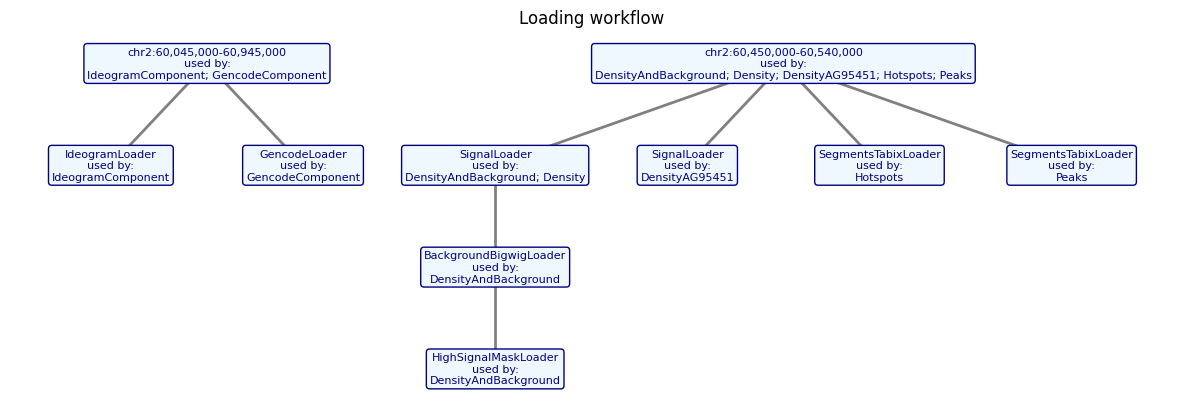

In [10]:
ax = plotter.get_loading_workflow(intervals).plot(
    font_size=8, font_color='navy',
    bbox=dict(boxstyle='round', facecolor='aliceblue', edgecolor='navy'),
    edges_kwargs=dict(edge_color='gray', width=2),
)
ax.set_title('Loading workflow')

## Data

`get_interval_data` returns a namedtuple of `DataBundle`s: each bundle is shown under its component name, with its own interval.

In [11]:
data = plotter.get_interval_data(intervals)
data

Loading data:   0%|          | 0/6 [00:00<?, ?it/s]

Loading data:  50%|█████     | 3/6 [00:14<00:14,  4.69s/it]

Loading data:  67%|██████▋   | 4/6 [00:21<00:10,  5.49s/it]

'https://regulome.altius.org/data/per_sample/AG95384/peaks/fdr0.05/AG95384.hotspots.fdr0.05.bed.gz' not found locally; treating it as remote. Reading the header via pysam (skiprows and header_char arguments are ignored).


Loading data:  83%|████████▎ | 5/6 [00:31<00:06,  6.93s/it]

'https://regulome.altius.org/data/per_sample/AG95384/peaks/fdr0.05/AG95384.peaks.fdr0.05.bed.gz' not found locally; treating it as remote. Reading the header via pysam (skiprows and header_char arguments are ignored).


Loading data: 100%|██████████| 6/6 [00:41<00:00,  8.03s/it]

Loading data: 100%|██████████| 6/6 [00:41<00:00,  6.96s/it]

**ComponentNamesTuple** · namedtuple with 7 fields, access as `.IdeogramComponent`, `[0]` or `.get('IdeogramComponent')`

<details><summary><b>IdeogramComponent</b>: DataBundle <code>chr2:60,045,000-60,945,000</code></summary>

- `ideogram_data`: `({'chr1': [(0, 2300000),…), (10400000, 200000)]})`

Access as `.ideogram_data` or `['ideogram_data']`

</details>

<details><summary><b>GencodeComponent</b>: DataBundle <code>chr2:60,045,000-60,945,000</code></summary>

- `gencode_annotation_file`: `'https://resources.altiu…notation.sorted.gff3.gz'`

Access as `.gencode_annotation_file` or `['gencode_annotation_file']`

</details>

<details><summary><b>DensityAndBackground</b>: DataBundle <code>chr2:60,450,000-60,540,000</code></summary>

- `fit_threshold`: ndarray 90000 float32
- `high_signal_mask`: ndarray 90000 bool
- `signal`: ndarray 90000 float32

Access as `.fit_threshold` or `['fit_threshold']`

</details>

<details><summary><b>Density</b>: DataBundle <code>chr2:60,450,000-60,540,000</code></summary>

- `signal`: ndarray 90000 float32

Access as `.signal` or `['signal']`

</details>

<details><summary><b>DensityAG95451</b>: DataBundle <code>chr2:60,450,000-60,540,000</code></summary>

- `signal`: ndarray 90000 float32

Access as `.signal` or `['signal']`

</details>

<details><summary><b>Hotspots</b>: DataBundle <code>chr2:60,450,000-60,540,000</code></summary>

- `intervals`: list (6 items)

Access as `.intervals` or `['intervals']`

</details>

<details><summary><b>Peaks</b>: DataBundle <code>chr2:60,450,000-60,540,000</code></summary>

- `intervals`: list (6 items)

Access as `.intervals` or `['intervals']`

</details>

In [12]:
data.DensityAndBackground

DataBundle <code>chr2:60,450,000-60,540,000</code>

- `fit_threshold`: ndarray 90000 float32
- `high_signal_mask`: ndarray 90000 bool
- `signal`: ndarray 90000 float32

Access as `.fit_threshold` or `['fit_threshold']`

Access by name like a dict, with a default for missing names.

In [13]:
data.get('Density')

DataBundle <code>chr2:60,450,000-60,540,000</code>

- `signal`: ndarray 90000 float32

Access as `.signal` or `['signal']`

In [14]:
data.get('NotAComponent', 'missing')

'missing'

## Plots

/Users/sabramov/Documents/VScodeProjects/genome-tools/genome_tools/plotting/__init__.py:441: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  mpatches.Rectangle(


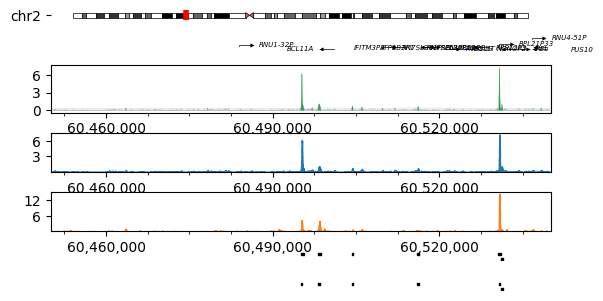

In [15]:
axes = plotter.plot_interval(data, fig_width=5)

Full region and a zoom side by side in one figure (`subplot_spec`), with a connector. Ideogram and GENCODE keep the large interval.

Loading data:   0%|          | 0/6 [00:00<?, ?it/s]

Loading data:  50%|█████     | 3/6 [00:23<00:23,  7.85s/it]

Loading data:  67%|██████▋   | 4/6 [00:30<00:15,  7.62s/it]

'https://regulome.altius.org/data/per_sample/AG95384/peaks/fdr0.05/AG95384.hotspots.fdr0.05.bed.gz' not found locally; treating it as remote. Reading the header via pysam (skiprows and header_char arguments are ignored).


Loading data:  83%|████████▎ | 5/6 [00:35<00:06,  6.82s/it]

'https://regulome.altius.org/data/per_sample/AG95384/peaks/fdr0.05/AG95384.peaks.fdr0.05.bed.gz' not found locally; treating it as remote. Reading the header via pysam (skiprows and header_char arguments are ignored).


Loading data: 100%|██████████| 6/6 [00:40<00:00,  6.31s/it]

Loading data: 100%|██████████| 6/6 [00:40<00:00,  6.83s/it]

/Users/sabramov/Documents/VScodeProjects/genome-tools/genome_tools/plotting/__init__.py:441: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  mpatches.Rectangle(


/Users/sabramov/Documents/VScodeProjects/genome-tools/genome_tools/plotting/__init__.py:441: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  mpatches.Rectangle(


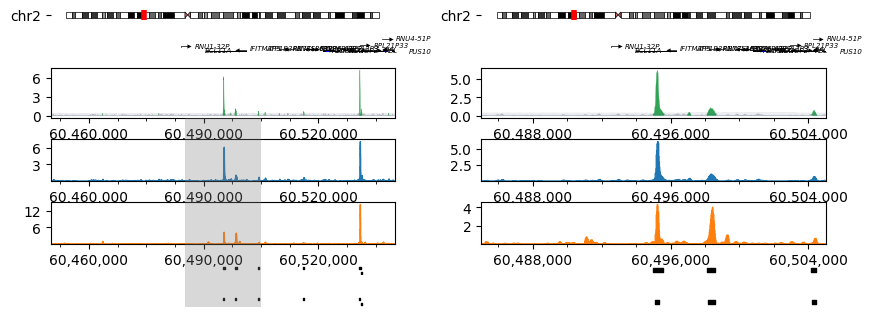

In [16]:
zoom = GenomicInterval.from_ucsc('chr2:60485000-60505000')
data_zoom = plotter.get_interval_data({'large': intervals['large'], 'small': zoom})

fig = plt.figure(figsize=(10, 4))
outer = fig.add_gridspec(1, 2, wspace=0.25)
axes_wide = plotter.plot_interval(data, subplot_spec=outer[0, 0])
axes_zoom = plotter.plot_interval(data_zoom, subplot_spec=outer[0, 1])
plotter.plot_connector(axes_wide, interval=zoom, start_component='DensityAndBackground',
                       type='area', extend_to_bottom=True)

The axes namedtuple: values without a markdown repr are shown as their repr.

In [17]:
axes_zoom

**ComponentNamesTuple** · namedtuple with 7 fields, access as `.IdeogramComponent`, `[0]` or `.get('IdeogramComponent')`

<b>IdeogramComponent</b>: <code>&lt;Axes: &gt;</code>

<b>GencodeComponent</b>: <code>&lt;Axes: &gt;</code>

<b>DensityAndBackground</b>: <code>&lt;Axes: &gt;</code>

<b>Density</b>: <code>&lt;Axes: &gt;</code>

<b>DensityAG95451</b>: <code>&lt;Axes: &gt;</code>

<b>Hotspots</b>: <code>&lt;Axes: &gt;</code>

<b>Peaks</b>: <code>&lt;Axes: &gt;</code>